# U.S. Retail Sales Forecasting Using Time Series Models



Retail sales forecasting helps businesses anticipate demand, plan inventory, allocate resources, and make informed decisions. Historical sales data can reveal long-term trends and repeating seasonal patterns, but sudden changes can make forecasting difficult.

This project explores monthly U.S. retail sales from January 1992 through June 2021. It compares two forecasting approaches:
Holt-Winters Exponential Smoothing and Seasonal Autoregressive Integrated Moving Average (SARIMA). 
The goal is to evaluate how well these models predict sales during a period of substantial change and understand the
limitations of relying on historical patterns.

This project demonstrates a workflow for evaluating sales forecasts and communicating their limitations. The analysis highlights why businesses should assess forecasting errors carefully, particularly when recent sales patterns differ substantially from historical trends.


In [27]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, r2_score


#### Load Data

In [28]:
# Load the dataset
df = pd.read_csv("us_retail_sales.csv")

# Display first few rows
df.head()

,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC
0,1992,146925,147223,146805,148032,149010,149800,150761.0,151067.0,152588.0,153521.0,153583.0,155614.0
1,1993,157555,156266,154752,158979,160605,160127,162816.0,162506.0,163258.0,164685.0,166594.0,168161.0
2,1994,167518,169649,172766,173106,172329,174241,174781.0,177295.0,178787.0,180561.0,180703.0,181524.0
3,1995,182413,179488,181013,181686,183536,186081,185431.0,186806.0,187366.0,186565.0,189055.0,190774.0
4,1996,189135,192266,194029,194744,196205,196136,196187.0,196218.0,198859.0,200509.0,200174.0,201284.0


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   YEAR    30 non-null     int64  
 1   JAN     30 non-null     int64  
 2   FEB     30 non-null     int64  
 3   MAR     30 non-null     int64  
 4   APR     30 non-null     int64  
 5   MAY     30 non-null     int64  
 6   JUN     30 non-null     int64  
 7   JUL     29 non-null     float64
 8   AUG     29 non-null     float64
 9   SEP     29 non-null     float64
 10  OCT     29 non-null     float64
 11  NOV     29 non-null     float64
 12  DEC     29 non-null     float64
dtypes: float64(6), int64(7)
memory usage: 3.2 KB


In [30]:
#Null check
df.isnull().sum()

YEAR    0
JAN     0
FEB     0
MAR     0
APR     0
MAY     0
JUN     0
JUL     1
AUG     1
SEP     1
OCT     1
NOV     1
DEC     1
dtype: int64

In [31]:
df.tail()

,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC
25,2017,416081,415503,414620,416889,414540,416505,416744.0,417179.0,426501.0,426933.0,431158.0,433282.0
26,2018,432148,434106,433232,435610,439996,438191,440703.0,439278.0,438985.0,444038.0,445242.0,434803.0
27,2019,440751,439996,447167,448709,449552,450927,454012.0,456500.0,452849.0,455486.0,457658.0,458055.0
28,2020,460586,459610,434281,379892,444631,476343,481627.0,483716.0,493327.0,493991.0,488652.0,484782.0
29,2021,520162,504458,559871,562269,548987,550782,NaN,NaN,NaN,NaN,NaN,NaN


##### The dataset goes from January 1992 to June 2021.After June 2021 data is missing.

>> Time series modeling needs a clear timeline. The model should understand that January 1992 comes before February 1992, then March 1992, and so on.When months are separate columns, Python sees them as different variables. We can convert them to long format, so the data follows a proper chronological order. This format allows Python to create a single date column, sort the observations by time, visualize trends, and prepare the data for forecasting models

In [32]:
# Convert wide monthly format into long format
monthly_data = df.melt(
    id_vars="YEAR",
    var_name="Month",
    value_name="Retail_Sales"
)

# Create month number mapping - Python can create a proper date more easily when it has the year and month number
month_map = {
    "JAN": 1, "FEB": 2, "MAR": 3, "APR": 4,
    "MAY": 5, "JUN": 6, "JUL": 7, "AUG": 8,
    "SEP": 9, "OCT": 10, "NOV": 11, "DEC": 12
}

monthly_data["Month_Num"] = monthly_data["Month"].map(month_map)

# Create proper date column
monthly_data["Date"] = pd.to_datetime(
    monthly_data["YEAR"].astype(str) + "-" + monthly_data["Month_Num"].astype(str) + "-01"
)

# Sort by date
monthly_data = monthly_data.sort_values("Date").reset_index(drop=True)

# Create time index for modeling
monthly_data["Time_Index"] = np.arange(len(monthly_data))

monthly_data.head()

,YEAR,Month,Retail_Sales,Month_Num,Date,Time_Index
0,1992,JAN,146925.0,1,1992-01-01,0
1,1992,FEB,147223.0,2,1992-02-01,1
2,1992,MAR,146805.0,3,1992-03-01,2
3,1992,APR,148032.0,4,1992-04-01,3
4,1992,MAY,149010.0,5,1992-05-01,4


In [33]:
monthly_data.head(20)

,YEAR,Month,Retail_Sales,Month_Num,Date,Time_Index
0,1992,JAN,146925.0,1,1992-01-01,0
1,1992,FEB,147223.0,2,1992-02-01,1
2,1992,MAR,146805.0,3,1992-03-01,2
3,1992,APR,148032.0,4,1992-04-01,3
4,1992,MAY,149010.0,5,1992-05-01,4
5,1992,JUN,149800.0,6,1992-06-01,5
6,1992,JUL,150761.0,7,1992-07-01,6
7,1992,AUG,151067.0,8,1992-08-01,7
8,1992,SEP,152588.0,9,1992-09-01,8
9,1992,OCT,153521.0,10,1992-10-01,9


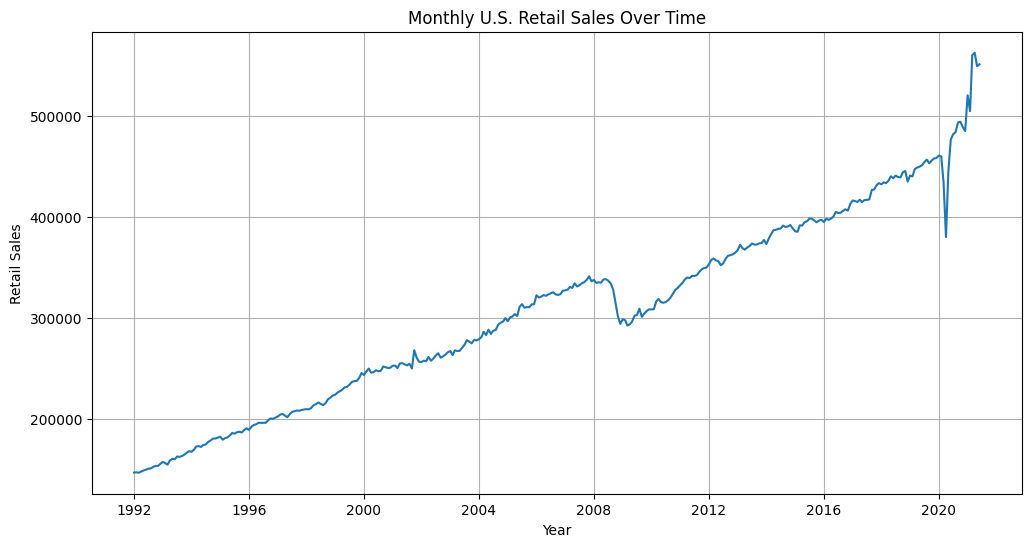

In [34]:
# Plot the full retail sales data
plt.figure(figsize=(12, 6))
plt.plot(monthly_data["Date"], monthly_data["Retail_Sales"])
plt.title("Monthly U.S. Retail Sales Over Time")
plt.xlabel("Year")
plt.ylabel("Retail Sales")
plt.grid(True)
plt.show()

>> The graph shows that U.S. retail sales increased over time from 1992 to 2021. Sales grew slowly in the beginning and became much higher in later years. There was a small drop around 2008–2009, likely due to the recession. There was also a sharp drop around 2020, likely due to COVID-19, but sales recovered quickly after that. Overall, the data shows a strong upward trend with some ups and downs.
>>
>> Since graph shows monthly data with a clear upward trend and seasonal pattern, Holt-Winters method could be used for time series data that has both trend and seasonality.
>>
>> Real-world data like that of demand data in any industry generally has a lot of seasonality and trends. When forecasting demands in such cases requires models which will account for the trend and seasonality in the data as the decision made by the business is going to be based on the result of this model. For such cases, Holt winter’s method is one of the many time series prediction methods which can be used for forecasting. (https://www.analyticsvidhya.com/blog/2021/08/holt-winters-method-for-time-series-analysis/)

### Split Data into Test and Train set
(Use the last year of data (July 2020 – June 2021) of data as test set and the rest as your training set)

In [35]:
# Split into training and test sets
# Test set: July 2020 through June 2021
test_start = "2020-07-01"
test_end = "2021-06-01"

train = monthly_data[monthly_data["Date"] < test_start]
test = monthly_data[
    (monthly_data["Date"] >= test_start) & 
    (monthly_data["Date"] <= test_end)
]

print("Training set size:", train.shape)
print("Test set size:", test.shape)

Training set size: (342, 6)
Test set size: (12, 6)


In [46]:
test.tail()

,YEAR,Month,Retail_Sales,Month_Num,Date,Time_Index,Predicted_Sales
349,2021,FEB,504458.0,2,2021-02-01,349,480303.309751
350,2021,MAR,559871.0,3,2021-03-01,350,480722.116062
351,2021,APR,562269.0,4,2021-04-01,351,481051.890431
352,2021,MAY,548987.0,5,2021-05-01,352,484572.109312
353,2021,JUN,550782.0,6,2021-06-01,353,484359.670539


### BUild the Holt-Winters model using Training data

The Holt-Winters model is used because retail sales data usually changes over time and also repeats seasonal patterns. Sales may generally increase over the years, and may also rise or drop during seasons. Holt-Winters can capture both of these patterns

In [36]:
# Build Holt-Winters model using additive trend and additive seasonality

hw_model = ExponentialSmoothing(
    train['Retail_Sales'],
    trend='add',
    seasonal='add',
    seasonal_periods=12
).fit(
    optimized=True,
    method='L-BFGS-B'
)

hw_forecast = hw_model.forecast(len(test))

In [37]:
# Forecast 12 months for the test period
test = test.copy()
test["Predicted_Sales"] = hw_fit.forecast(steps=len(test))

# Display actual and predicted values
test[["Date", "Retail_Sales", "Predicted_Sales"]]

,Date,Retail_Sales,Predicted_Sales
342,2020-07-01,481627.0,474567.565026
343,2020-08-01,483716.0,475414.392468
344,2020-09-01,493327.0,476022.831549
345,2020-10-01,493991.0,477202.575306
346,2020-11-01,488652.0,478050.117973
347,2020-12-01,484782.0,479028.123668
348,2021-01-01,520162.0,479926.908189
349,2021-02-01,504458.0,480303.309751
350,2021-03-01,559871.0,480722.116062
351,2021-04-01,562269.0,481051.890431


In [38]:
#Calculate RMSE
rmse = np.sqrt(mean_squared_error(test["Retail_Sales"], test["Predicted_Sales"]))

print("RMSE:", rmse)

RMSE: 45156.97171858639


>> The prediction table shows that the model predicted around 475,000 to 484,000, but the actual sales increased much higher in 2021(over 510000), especially from March to June. This means the model captured the general trend, but it did not fully capture the strong post-2020 increase in retail sales.

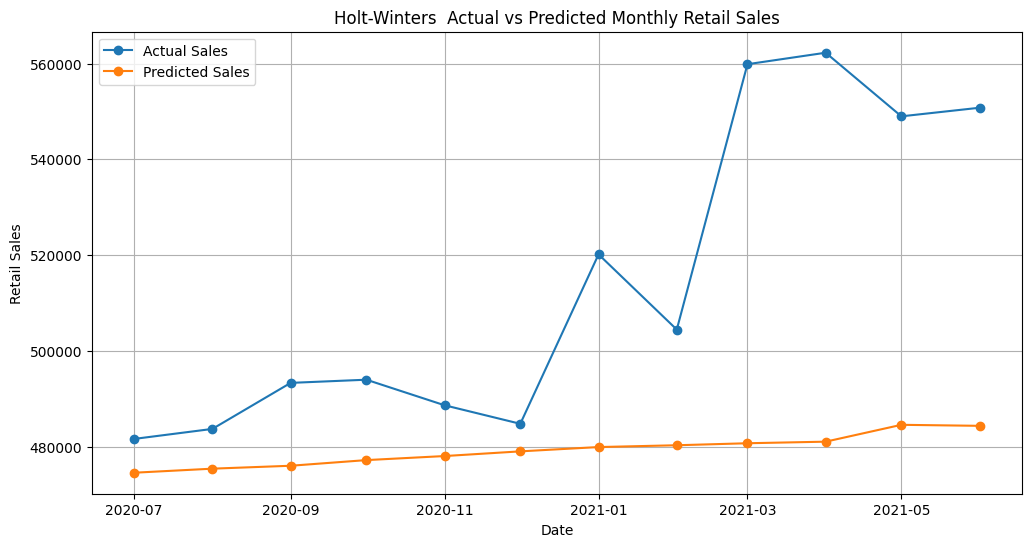

In [39]:
plt.figure(figsize=(12,6))

plt.plot(test["Date"], test["Retail_Sales"], marker="o", label="Actual Sales")
plt.plot(test["Date"], test["Predicted_Sales"], marker="o", label="Predicted Sales")

plt.title("Holt-Winters  Actual vs Predicted Monthly Retail Sales")
plt.xlabel("Date")
plt.ylabel("Retail Sales")
plt.legend()
plt.grid(True)
plt.show()

>> The graph compares actual and predicted retail sales from July 2020 to June 2021. The predicted sales line is smoother and increases slowly over time. The actual sales line is much higher and has bigger changes, especially in 2021. This shows that the Holt-Winters model captured the general upward direction

In [40]:
from sklearn.metrics import r2_score

r2 = r2_score(test["Retail_Sales"], test["Predicted_Sales"])

print("R-squared:", r2)

R-squared: -1.141335492314814


#### Let’s try SARIMA next — this is a good choice because Holt-Winters model underestimated the 2021 jump and gave a high RMSE. 
#### Seasonal Autoregressive Integrated Moving Average, SARIMA or Seasonal ARIMA, is an extension of ARIMA that explicitly supports univariate time series data with a seasonal component. https://machinelearningmastery.com/sarima-for-time-series-forecasting-in-python/

In [41]:
# Build SARIMA model
## "Retail_Sales" is the target variable we want to forecast.
    # The model learns from the Retail_Sales values in the training dataset
# order=(p, d, q)
    # p = 1: uses the previous sales value to help predict the next value
    # d = 1: applies first differencing to remove trend and make the data more stable
    # q = 1: uses previous forecast errors to improve future predictions
 # seasonal_order=(P, D, Q, s)
    # P = 1: uses previous seasonal patterns
    # D = 1: applies seasonal differencing to remove repeating yearly patterns
    # Q = 1: uses previous seasonal forecast errors
    # s = 12: because the data is monthly and there are 12 months in a year
# This allows the model more flexibility.
    # Sometimes real-world data is not perfectly stationary.


sarima_model = SARIMAX(
    train["Retail_Sales"],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Fit the model
sarima_fit = sarima_model.fit(disp=False)

print(sarima_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                       Retail_Sales   No. Observations:                  342
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood               -3210.179
Date:                            Sun, 10 May 2026   AIC                           6430.359
Time:                                    19:13:39   BIC                           6449.122
Sample:                                         0   HQIC                          6437.855
                                            - 342                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5570      0.083      6.676      0.000       0.393       0.721
ma.L1         -0.7234      0.079   

In [42]:
#Forecast
sarima_forecast = sarima_fit.forecast(steps=len(test))

In [43]:
#compare actual vs predicted:
comparison = test[['Retail_Sales']].copy()
comparison['SARIMA_Predicted'] = sarima_forecast.values

comparison

,Retail_Sales,SARIMA_Predicted
342,481627.0,472662.232092
343,483716.0,469915.761861
344,493327.0,467295.167295
345,493991.0,469497.544028
346,488652.0,470815.334264
347,484782.0,467042.062210
348,520162.0,470290.324564
349,504458.0,469675.930274
350,559871.0,460669.576182
351,562269.0,436617.407925


In [44]:
#CAlculate RMSE


sarima_rmse = np.sqrt(mean_squared_error(
    comparison['Retail_Sales'],
    comparison['SARIMA_Predicted']
))

print("SARIMA RMSE:", sarima_rmse)

SARIMA RMSE: 59819.071047161364


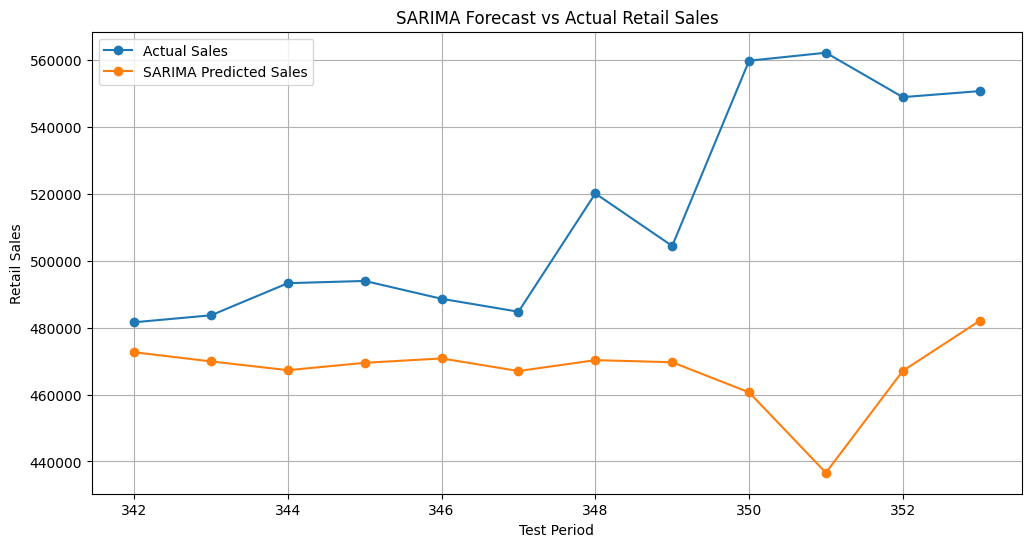

In [45]:
#Plot tge Actual vs Predicted


plt.figure(figsize=(12, 6))

plt.plot(test.index, comparison['Retail_Sales'], marker='o', label='Actual Sales')
plt.plot(test.index, comparison['SARIMA_Predicted'], marker='o', label='SARIMA Predicted Sales')

plt.title('SARIMA Forecast vs Actual Retail Sales')
plt.xlabel('Test Period')
plt.ylabel('Retail Sales')
plt.legend()
plt.grid(True)
plt.show()

>> Since lower RMSE means better prediction, Holt-Winters performed better than SARIMA for this test set.Both models underestimated the actual retail sales and did not capture the periodic drop and increse in data. Holt-Winters gave an RMSE of 45,156.97, while SARIMA gave an RMSE of 59,819.07.